# Task 5 (Advanced) - Machine Learning Classification Model
- **Description:** Building a machine learning model to classify Netflix content based on available features.
- **Goal:** Predicting whether a title is a **Movie** or a **TV Show**.

## Step 1: Selecting and preparing features

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

data = pd.read_csv("Cleaned_Netflix_Dataset.csv")

# Target: 1 = TV Show, 0 = Movie
y = (data["type"] == "TV Show").astype(int)
print(data["type"].value_counts())

type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [2]:
# Director has too many unique names, so only keep whether it is known
data["known_director"] = (data["director"] != "Unknown").astype(int)

categorical = ["rating", "primary_country"]
numeric = ["release_year", "year_added", "month_added", "years_to_netflix",
           "genre_count", "country_count", "known_director"]

X = data[categorical + numeric]
X.head()

,rating,primary_country,release_year,year_added,month_added,years_to_netflix,genre_count,country_count,known_director
0,PG-13,United States,2020,2021,9,1,1,1,1
1,TV-MA,France,2021,2021,9,0,3,1,1
2,TV-MA,United States,2021,2021,9,0,3,1,1
3,TV-PG,Brazil,2021,2021,9,0,2,1,1
4,TV-MA,United States,1993,2021,9,28,3,1,1


**Features left out on purpose**
- `duration`, `duration_value`, `duration_unit`: movies are in minutes and TV shows in seasons, so they would give away the answer.
- `listed_in`, `primary_genre`: category names contain words like "Movies" and "TV Shows".
- `show_id`, `title`: identifiers, not useful for prediction.

## Step 2: Spliting data into training and testing sets

In [3]:
# 80% training / 20% testing, keeping the Movie/TV Show ratio the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (7032, 9)
Testing set : (1758, 9)


## Step 3: Training classification models

In [4]:
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), categorical),
    ("num", StandardScaler(), numeric),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

trained = {}
for name, model in models.items():
    trained[name] = make_pipeline(preprocess, model).fit(X_train, y_train)
    print(name, "trained")

Logistic Regression trained
Decision Tree trained
Random Forest trained


## Step 4: Evaluate model performance

In [5]:
results = []
predictions = {}
for name, pipe in trained.items():
    pred = pipe.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
    })

results = pd.DataFrame(results).round(3)
results

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.948,0.932,0.895,0.913
1,Decision Tree,0.944,0.924,0.889,0.906
2,Random Forest,0.952,0.931,0.908,0.919


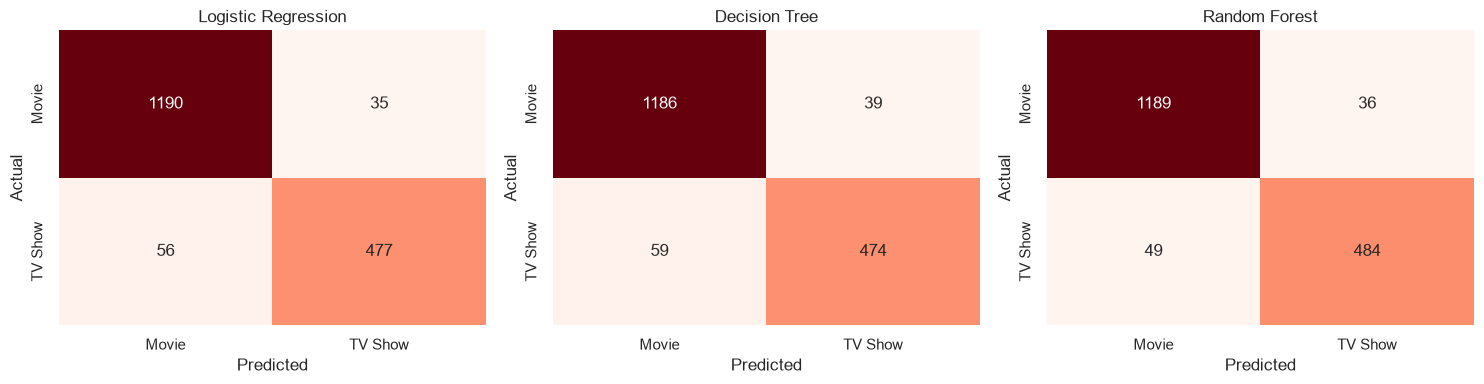

In [6]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Reds", cbar=False,
                xticklabels=["Movie", "TV Show"], yticklabels=["Movie", "TV Show"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [7]:
best = results.sort_values("Accuracy", ascending=False).iloc[0]["Model"]
print("Best model:", best, "\n")
print(classification_report(y_test, predictions[best], target_names=["Movie", "TV Show"]))

Best model: Random Forest 

              precision    recall  f1-score   support

       Movie       0.96      0.97      0.97      1225
     TV Show       0.93      0.91      0.92       533

    accuracy                           0.95      1758
   macro avg       0.95      0.94      0.94      1758
weighted avg       0.95      0.95      0.95      1758



## Step 5: Comparing model accuracy

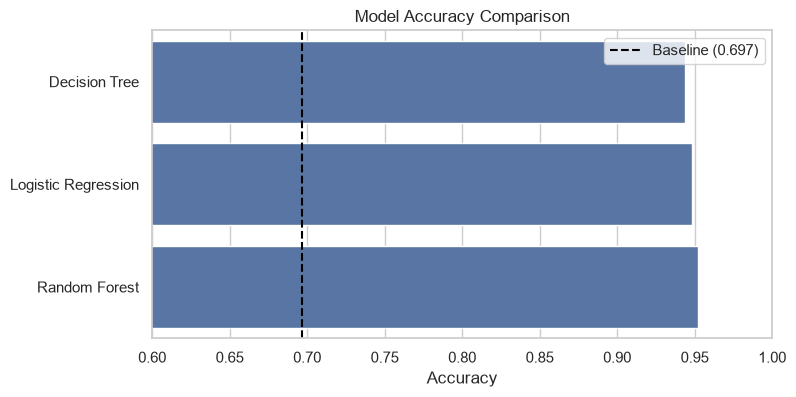

In [8]:
# Baseline: always predicting the most common class (Movie)
baseline = 1 - y_test.mean()

comparison = results.set_index("Model")["Accuracy"].sort_values()
plt.figure(figsize=(8, 4))
sns.barplot(x=comparison.values, y=comparison.index)
plt.axvline(baseline, color="black", linestyle="--", label=f"Baseline ({baseline:.3f})")
plt.xlim(0.6, 1.0)
plt.xlabel("Accuracy")
plt.ylabel("")
plt.title("Model Accuracy Comparison")
plt.legend()
plt.show()

### Conclusion
- **Best model:** Random Forest reached the highest accuracy (**95.2%**), followed by Logistic Regression (94.8%) and Decision Tree (94.4%). All three are far above the baseline of **69.7%** (always predicting "Movie").
- **Class results:** For Random Forest, Movies are predicted slightly better (precision 0.96, recall 0.97) than TV Shows (precision 0.93, recall 0.91), which is expected because there are fewer TV Shows. It misclassified 36 movies as TV shows and 49 TV shows as movies out of 1,758 test titles.
- **Comparison:** The three models are very close (less than 1 percentage point apart), so the choice between them is not clear-cut. These results come from a single train/test split.
- **Why it works:** Ratings such as R and PG-13 only appear on movies, and the release year, year added and country also differ between movies and TV shows.